# Exp 8 – Advanced Model Optimization – Random Forest & XGBoost

# Exp 8(2) – Hyperparameter-Tuned Random Forest | Validation-Based Threshold Optimization

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Missing categorical values are replaced with a constant value and encoded using One-Hot Encoding (OHE).
5. Missing numerical values are imputed using the median.
6. Class imbalance is handled using class_weight='balanced'.
7. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
8. Regularization is applied using parameters such as max_depth, min_samples_split, and min_samples_leaf.
9. The best model generates churn probabilities on the validation set.
10. A fine-grained threshold analysis (0.05–0.95) is performed to select the threshold with the highest F1 Score.
11. The selected threshold is applied to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
12. Model performance is evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
13. Cross-validation performance is evaluated, and feature importance is analysed to identify the most influential features.

Exp 8(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp8

## 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. SEPARATE FEATURES AND TARGET

In [3]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore').copy()
y = df['churn'].copy()

print("Total Missing Values:", X.isna().sum().sum())
print("\n==== TARGET DISTRIBUTION ====")
print(y.value_counts())
print("\n==== TARGET PERCENTAGE ====")
print((y.value_counts(normalize=True) * 100).round(2))

Total Missing Values: 33864

==== TARGET DISTRIBUTION ====
churn
0    13187
1     1419
Name: count, dtype: int64

==== TARGET PERCENTAGE ====
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 2. ORIGINAL TRAIN TEST SPLIT

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


## 3. INTERNAL TRAIN VALIDATION SPLIT

In [5]:
# Test data remains untouched.
# Validation data is used for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)


## 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))


Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101


## 5. PREPROCESSING PIPELINE

In [7]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', categorical_pipeline, categorical_cols),
        ('numerical', numerical_pipeline, numerical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

## 6. RANDOM FOREST PIPELINE

In [8]:
rf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

## 7. STRATIFIED CROSS VALIDATION

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 8. HYPERPARAMETER SEARCH SPACE

In [10]:
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.5]
}

## 9. RANDOMIZED SEARCH CV

In [11]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

## 10. FIT RANDOMIZED SEARCH

In [12]:
random_search.fit(X_fit, y_fit)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [5, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [2, 5, ...], 'model__min_samples_split': [5, 10, ...], ...}"
,n_iter,25
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## 11. BEST HYPERPARAMETERS

In [13]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)


==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None}

Best CV PR-AUC:
0.2735256167859131


## 12. BEST RANDOM FOREST MODEL

In [14]:
best_rf_pipeline = random_search.best_estimator_

## 13. RANDOMIZED SEARCH RESULTS

In [15]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__min_samples_split',
        'param_model__min_samples_leaf',
        'param_model__max_features',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_train_score  mean_test_score  std_test_score
                       500                   None                               5                              5                       0.5            0.9993           0.2735          0.0285
                       300                   None                              30                             10                       0.5            0.9609           0.2636          0.0263
                       200                     15                              20                              2                       0.5            0.9903           0.2606          0.0274
                       300                     15                              30                             15                       0.5            0.9198           0.2571          0.0240
    

## 14. VALIDATION PROBABILITIES

In [16]:
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

## 15. PRECISION RECALL CURVE

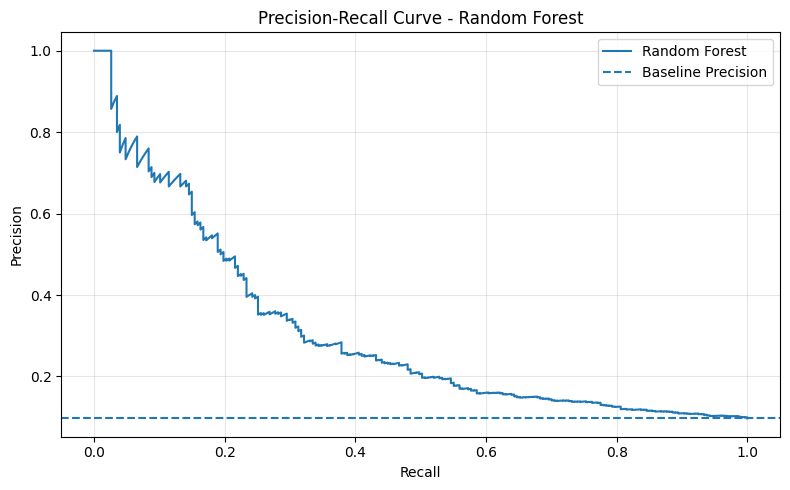

In [17]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Random Forest'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. FINE-GRAINED THRESHOLD ANALYSIS

In [18]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1020  0.9736    0.1847
      0.06     0.1028  0.9471    0.1855
      0.07     0.1059  0.9339    0.1903
      0.08     0.1094  0.9075    0.1953
      0.09     0.1135  0.8767    0.2010
      0.10     0.1176  0.8458    0.2066
      0.11     0.1205  0.8062    0.2096
      0.12     0.1266  0.7930    0.2183
      0.13     0.1337  0.7753    0.2281
      0.14     0.1385  0.7445    0.2336
      0.15     0.1402  0.7048    0.2339
      0.16     0.1485  0.6828    0.2439
      0.17     0.1510  0.6432    0.2446
      0.18     0.1597  0.6211    0.2541
      0.19     0.1650  0.5859    0.2575
      0.20     0.1730  0.5595    0.2643
      0.21     0.1876  0.5463    0.2793
      0.22     0.1983  0.5286    0.2885
      0.23     0.2039  0.5022    0.2901
      0.24     0.2157  0.4846    0.2985
      0.25     0.2304  0.4670    0.3086
      0.26     0.2353  0.4405    0.3067
      0.27     0.2513  0.4317    0.31

## 17. THRESHOLD PERFORMANCE VISUALIZATION

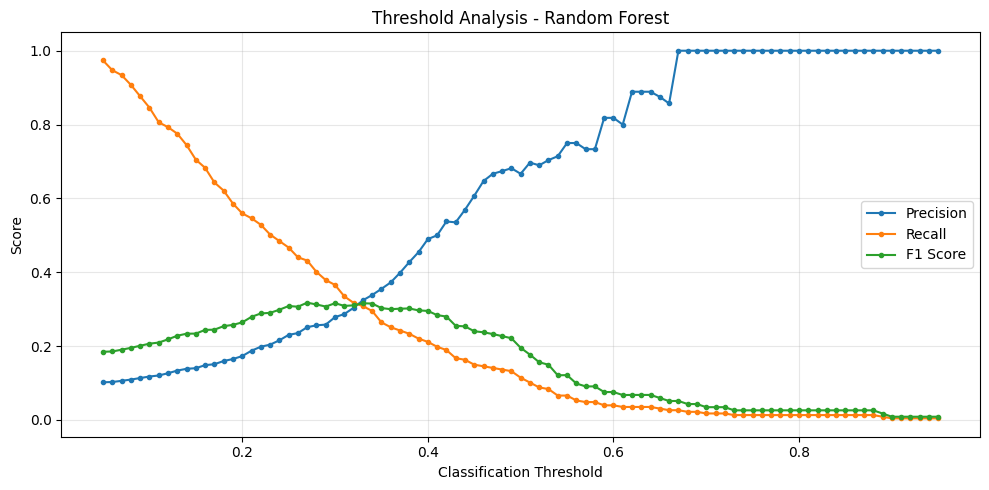

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 18. SELECT BEST THRESHOLD

In [20]:
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])


==== BEST THRESHOLD ====
Best Threshold: 0.27
Threshold    0.270000
Precision    0.251282
Recall       0.431718
F1 Score     0.317666
Name: 22, dtype: float64


## 19. DEFINE METRIC FUNCTION

In [21]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

## 20. TRAINING PREDICTIONS

In [22]:
y_prob_train = best_rf_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

## 21. VALIDATION PREDICTIONS

In [23]:
y_pred_val = (y_prob_val >= best_threshold).astype(int)

## 22. TEST PREDICTIONS

In [24]:
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

## 23. CALCULATE METRICS

In [25]:
train_metrics = calc_metrics(
    y_fit,
    y_pred_train,
    y_prob_train
)

validation_metrics = calc_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

## 24. PRINT TRAIN METRICS

In [26]:
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9617
Precision   : 0.7172
Recall      : 1.0000
F1 Score    : 0.8353
ROC-AUC     : 0.9999
PR-AUC      : 0.9993


## 25. PRINT VALIDATION METRICS

In [27]:
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8199
Precision   : 0.2513
Recall      : 0.4317
F1 Score    : 0.3177
ROC-AUC     : 0.6940
PR-AUC      : 0.3059


## 26. PRINT TEST METRICS

In [28]:
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8207
Precision   : 0.2571
Recall      : 0.4472
F1 Score    : 0.3265
ROC-AUC     : 0.6998
PR-AUC      : 0.3426


## 27. CONFUSION MATRIX

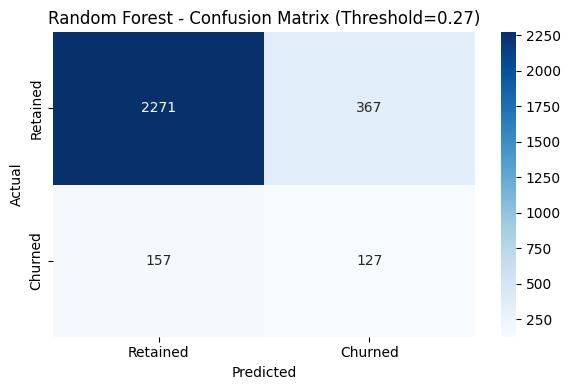

In [29]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Random Forest - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

## 28. CLASSIFICATION REPORT

In [30]:
print("\n==== CLASSIFICATION REPORT ====")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.94      0.86      0.90      2638
     Churned       0.26      0.45      0.33       284

    accuracy                           0.82      2922
   macro avg       0.60      0.65      0.61      2922
weighted avg       0.87      0.82      0.84      2922



## 29. CROSS VALIDATION PERFORMANCE

In [31]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

## 30. CROSS VALIDATION TRAIN SCORES

In [32]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9992, Std: 0.0004
train_Precision - Mean: 0.9921, Std: 0.0039
train_Recall - Mean: 1.0000, Std: 0.0000
train_F1 - Mean: 0.9960, Std: 0.0020
train_ROC_AUC - Mean: 0.9999, Std: 0.0000
train_PR_AUC - Mean: 0.9993, Std: 0.0006


## 31. CROSS VALIDATION VALIDATION SCORES

In [33]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9060, Std: 0.0027
test_Precision - Mean: 0.6025, Std: 0.0800
test_Recall - Mean: 0.0903, Std: 0.0214
test_F1 - Mean: 0.1567, Std: 0.0346
test_ROC_AUC - Mean: 0.6892, Std: 0.0258
test_PR_AUC - Mean: 0.2735, Std: 0.0285


## 32. FEATURE IMPORTANCE

In [34]:
rf_model = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))


==== TOP 20 IMPORTANT FEATURES ====
                   Feature  Importance
        margin_net_pow_ele    0.080522
   forecast_meter_rent_12m    0.037018
      cons_last_month_diff    0.033944
       forecast_cons_ratio    0.031551
    margin_per_consumption    0.029490
          margin_per_power    0.026130
              months_activ    0.025075
price_consumption_exposure    0.023920
   price_power_interaction    0.023053
     consumption_per_power    0.022417
         months_modif_prod    0.021085
     cons_last_month_ratio    0.019899
                   pow_max    0.018998
         forecast_cons_12m    0.018566
        forecast_cons_diff    0.018259
        margin_per_product    0.018151
                  cons_12m    0.017617
   var_year_price_off_peak    0.016581
       forecast_year_ratio    0.015184
            price_off_peak    0.015040


## 33. FEATURE IMPORTANCE VISUALIZATION

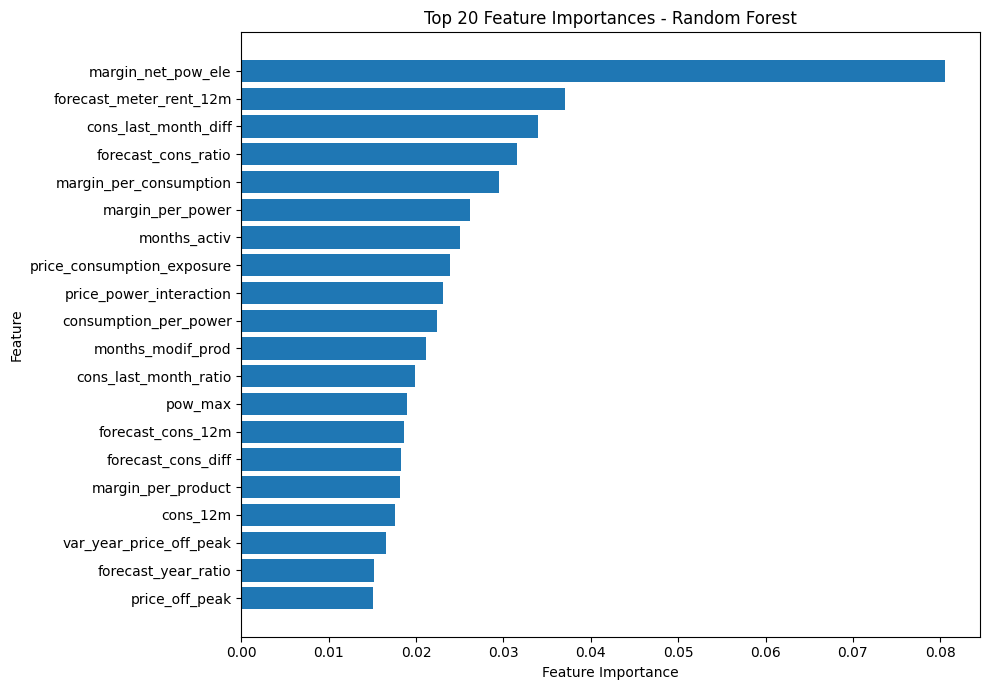

In [35]:
top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()

# **Observation: Exp 8(2) – Hyperparameter-Tuned Random Forest | Validation-Based Threshold Optimization**

**1. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 500
  - `min_samples_split`: 5
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: None
- Best CV PR-AUC: **27.35%**

**Observation:**

- Carried forward the best-performing Random Forest configuration from Exp2.
- Used a separate 64:16:20 fit-validation-test split.
- CV PR-AUC is lower than Exp2 (30.55%).
- Training performance remains extremely high, indicating overfitting.

**2. Model Performance – Test Data**

- Accuracy: **82.07%**
- Precision: **25.71%**
- Recall: **44.72%**
- F1 Score: **32.65%**
- ROC-AUC: **69.98%**
- PR-AUC: **34.26%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.27**, based on the highest F1 score in the threshold analysis.
- At threshold 0.27 (threshold validation):
  - Precision: 25.13%
  - Recall: 43.17%
  - F1 Score: 31.77%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.27)**

- True Negatives: 2,271
- False Positives: 367
- False Negatives: 157
- True Positives: 127

**Observation:**

- Model correctly identifies 127 churn customers out of 284.
- It misses 157 actual churn customers.
- Achieves the highest recall among all previous experiments.
- However, false positives are relatively high (367).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 34.26% is the second-highest among all experiments, after Exp2 (35.75%).

**6. Cross-Validation Results**

- Training PR-AUC: 99.93%
- Validation accuracy: 90.60%
- Validation precision: 60.25%
- Validation recall: 9.03%
- Validation F1: 15.67%
- Validation ROC-AUC: 68.92%
- Validation PR-AUC: 27.35%

**Observation:**

- Significant training-validation performance gap indicates severe overfitting.
- Validation recall is extremely low at the default 0.50 threshold.
- Despite overfitting, test PR-AUC is relatively strong.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- cons_last_month_diff
- forecast_cons_ratio
- margin_per_consumption
- margin_per_power
- months_activ
- price_consumption_exposure
- price_power_interaction
- consumption_per_power

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature.
- Feature importance patterns are consistent with earlier Random Forest experiments.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-RF |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- | -------- | ---------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        | 82.75%   | 82.07%     |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        | 23.68%   | 25.71%     |
| Recall    | 36.97%           | 34.86%              | 38.73%                | 28.52%       | 32.39%                 | 31.34%        | 34.86%   | **44.72%** |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        | 28.21%   | 32.65%     |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        | 66.45%   | 69.98%     |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        | 20.13%   | 34.26%     |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        | 20.85%   | 27.35%     |

**Observation:**

- Exp8(2) achieves the highest recall (44.72%) among all experiments.
- Its PR-AUC (34.26%) is the second-highest, after Exp2 (35.75%).
- However, precision is relatively low at 25.71%.
- Exp2 maintains a better overall balance between precision and recall.
- Exp8(2) identifies more churn customers but generates more false positives.
- Exp4 achieves the highest accuracy and precision.

**Final Conclusion – Exp 8(2) Random Forest**

- Achieves a test PR-AUC of 34.26%, close to the best model.
- Achieves the highest recall (44.72%) among all experiments.
- Correctly identifies 127 churn customers out of 284.
- However, precision is only 25.71%, with 367 false positives.
- Significant overfitting remains a concern.
- The validation-based threshold optimization provides a separate evaluation workflow from the original Exp2 experiment.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), with better precision.

However, Exp8(2) is a strong alternative when identifying more churn customers is the priority, even at the cost of additional false positives.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.27 threshold. Compare classification metrics cautiously.

**One important clarification:** Exp8(2) uses a separate 64:16:20 split, so its test results should be treated as a separate evaluation rather than a perfectly controlled comparison with experiments using a different split. Also, the reported threshold-validation metrics (25.13% precision, 43.17% recall and 31.77% F1) differ from the final test metrics.